In [102]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris

data = load_iris()
df = pd.DataFrame(data.data, columns=data.feature_names)

df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


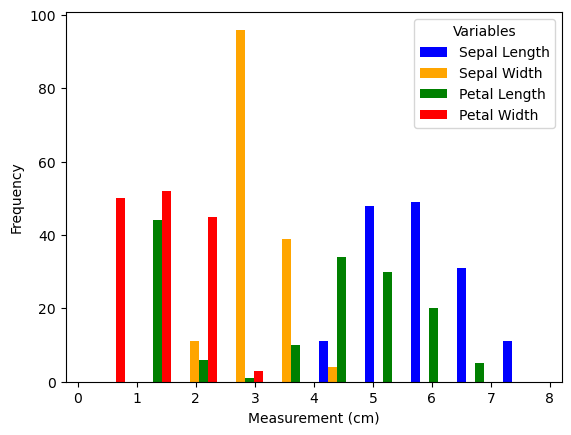

In [103]:

colors = ['blue', 'orange', 'green', 'red']

plt.hist([df["sepal length (cm)"], 
          df["sepal width (cm)"], 
          df["petal length (cm)"], 
          df["petal width (cm)"]], 
         label=[
             "Sepal Length",
             "Sepal Width",
             "Petal Length",
             "Petal Width"], 
        color=colors)



plt.xlabel("Measurement (cm)")
plt.ylabel("Frequency")

plt.legend(title="Variables")

plt.savefig("first_hist.png")

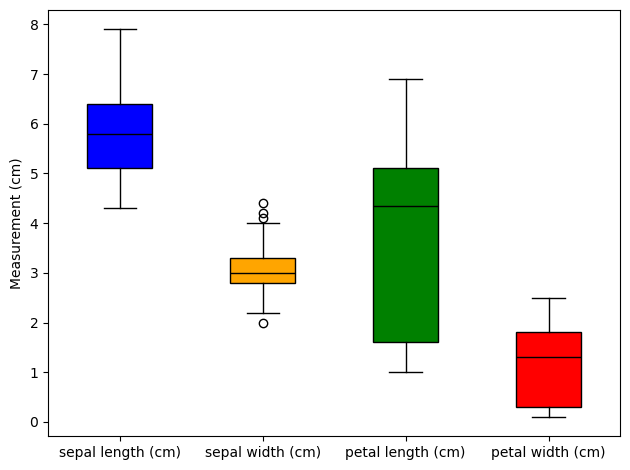

In [104]:
import matplotlib.pyplot as plt

colors = ['blue', 'orange', 'green', 'red']

box = plt.boxplot(
    [df[col] for col in df.columns],
    patch_artist=True,
    tick_labels=df.columns,
    medianprops=dict(color='black', linewidth=1)
)

for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)

plt.ylabel("Measurement (cm)")
#plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("first_boxplot.png")

plt.show()


In [105]:
mean=(df.sum())/len(df)
var=df.var(ddof=0)
stdev= np.sqrt(var)
std_data= (df-mean)/stdev

print(std_data)



     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0            -0.900681          1.019004          -1.340227         -1.315444
1            -1.143017         -0.131979          -1.340227         -1.315444
2            -1.385353          0.328414          -1.397064         -1.315444
3            -1.506521          0.098217          -1.283389         -1.315444
4            -1.021849          1.249201          -1.340227         -1.315444
..                 ...               ...                ...               ...
145           1.038005         -0.131979           0.819596          1.448832
146           0.553333         -1.282963           0.705921          0.922303
147           0.795669         -0.131979           0.819596          1.053935
148           0.432165          0.788808           0.933271          1.448832
149           0.068662         -0.131979           0.762758          0.790671

[150 rows x 4 columns]


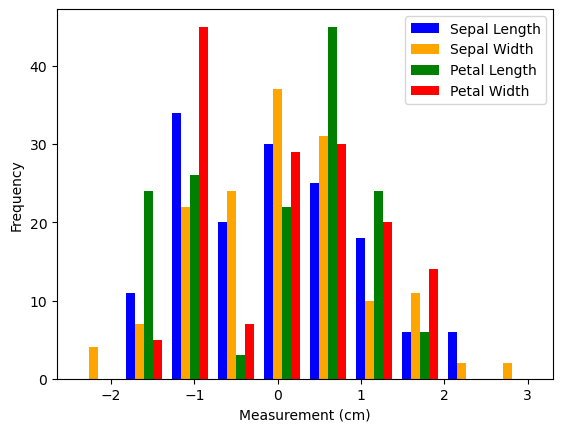

In [107]:
colors = ['blue', 'orange', 'green', 'red']

plt.hist(std_data,
         label=[
             "Sepal Length",
             "Sepal Width",
             "Petal Length",
             "Petal Width"], 
        color=colors)
plt.xlabel("Measurement (cm)")
plt.ylabel("Frequency")
plt.legend()
#plt.savefig("second_hist.png")

plt.show()

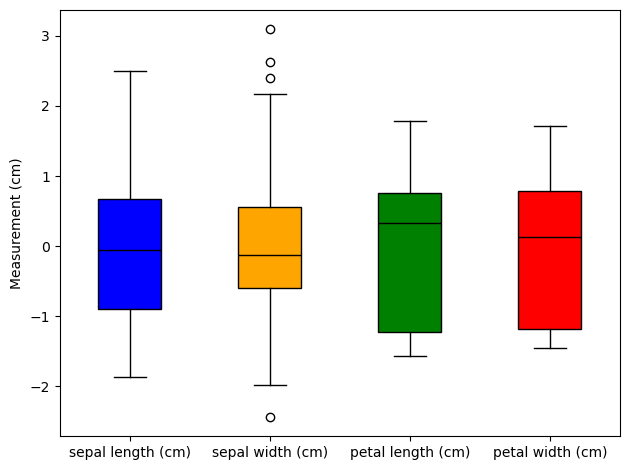

In [108]:
import matplotlib.pyplot as plt

colors = ['blue', 'orange', 'green', 'red']

box = plt.boxplot(
    [std_data[col] for col in std_data.columns],
    patch_artist=True,
    tick_labels=df.columns,
    medianprops=dict(color='black', linewidth=1)
)

for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)

plt.ylabel("Measurement (cm)")
plt.tight_layout()

#plt.savefig("second_boxplot.png")
plt.show()


In [109]:
def covariance(x, y):
    xmean = x.mean()
    ymean = y.mean()
    cov = ((x - xmean) * (y - ymean)).sum() / len(x)

    return cov

def covariance_matrix(df):
    num_features = len(df.columns)
    cov_matrix = np.zeros((num_features, num_features))

    for i in range(num_features):
        for j in range(num_features):

            x = df.iloc[:, i]
            y = df.iloc[:, j]

            cov_matrix[i, j] = covariance(x, y)

    return pd.DataFrame(
        cov_matrix,
        index=df.columns,
        columns=df.columns
    )

cov_original = covariance_matrix(df)

cov_standardised = covariance_matrix(std_data)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)


print(cov_original.round(3))
print(cov_standardised.round(3))

                   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
sepal length (cm)              0.681            -0.042              1.266             0.513
sepal width (cm)              -0.042             0.189             -0.327            -0.121
petal length (cm)              1.266            -0.327              3.096             1.287
petal width (cm)               0.513            -0.121              1.287             0.577
                   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
sepal length (cm)              1.000            -0.118              0.872             0.818
sepal width (cm)              -0.118             1.000             -0.428            -0.366
petal length (cm)              0.872            -0.428              1.000             0.963
petal width (cm)               0.818            -0.366              0.963             1.000


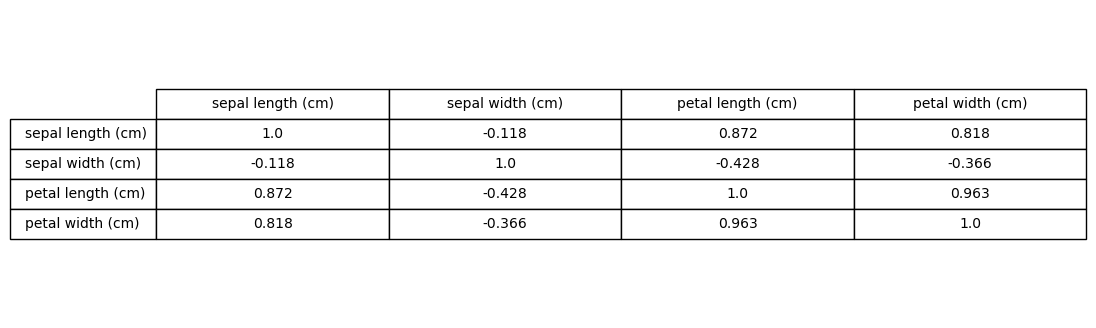

In [110]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.axis('off')

table = ax.table(
    cellText=cov_standardised.round(3).values,
    rowLabels=cov_standardised.index,
    colLabels=cov_standardised.columns,
    cellLoc='center',
    loc='center'
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.8)

#plt.savefig("standardised_covariance_matrix.png",
            #dpi=300, bbox_inches='tight')

plt.show()

Eigenvalues: [2.91849782 0.91403047 0.14675688 0.02071484]
     Eigenvalue                          Eigenvectors
PC1    2.918498     [0.5211, -0.2693, 0.5804, 0.5649]
PC2    0.914030  [-0.3774, -0.9233, -0.0245, -0.0669]
PC3    0.146757     [-0.7196, 0.2444, 0.1421, 0.6343]
PC4    0.020715    [0.2613, -0.1235, -0.8014, 0.5236]
variance of: 
 PC1: 72.9624455% 
 PC2: 22.85076175% 
 PC3: 3.6689220000000002% 
 PC4: 0.5178710000000001%


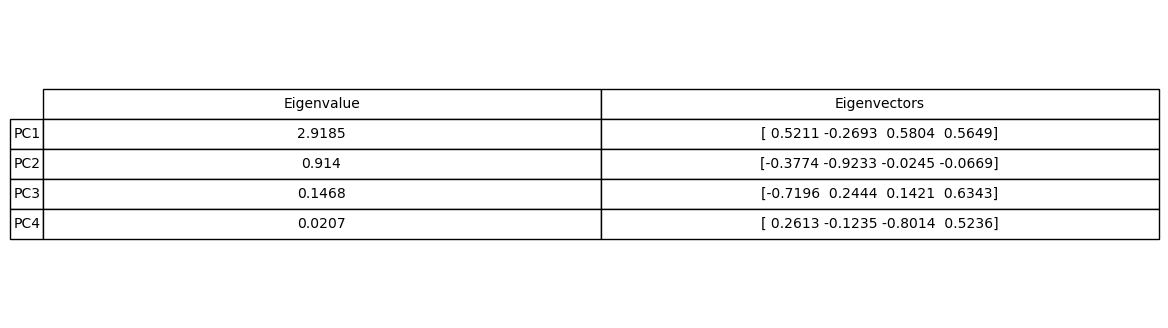

In [111]:
from numpy.linalg import eig

array = cov_standardised.values

eigenvalue,eigenvector=eig(array)

print('Eigenvalues:', eigenvalue)
#print('Eigenvectors:', eigenvector)

magnitudes=[]
for i in range(len(eigenvector)):
    magnitude_i = 0

    for j in range(len(eigenvector[i])):
        coefficient_ij = eigenvector[i,j]
        magnitude_i = magnitude_i+(coefficient_ij**2)

    magnitudes.append(np.sqrt(magnitude_i.round(3)))
    
eigen_results = pd.DataFrame({
    'Eigenvalue': eigenvalue,
#    'Magnitude': magnitudes,    
    'Eigenvectors': [eigenvector[:, i].round(4) for i in range(len(eigenvalue))]
}, index=['PC1', 'PC2', 'PC3', 'PC4'])

print(eigen_results)

variance_PC1= (2.91849782/4)*100
variance_PC2= (0.91403047/4)*100
variance_PC3= (0.14675688/4)*100
variance_PC4= (0.02071484/4)*100


print(f"variance of: \n PC1: {variance_PC1}% \n PC2: {variance_PC2}% \n PC3: {variance_PC3}% \n PC4: {variance_PC4}%")


fig, ax = plt.subplots(figsize=(12, 4))

ax.axis('off')

table = ax.table(
    cellText=eigen_results.round(4).values,
    rowLabels=eigen_results.index,
    colLabels=eigen_results.columns,
    cellLoc='center',
    loc='center'
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.8)

#plt.savefig("eigenvalue_magnitude_eigenvectors.png")
plt.show()

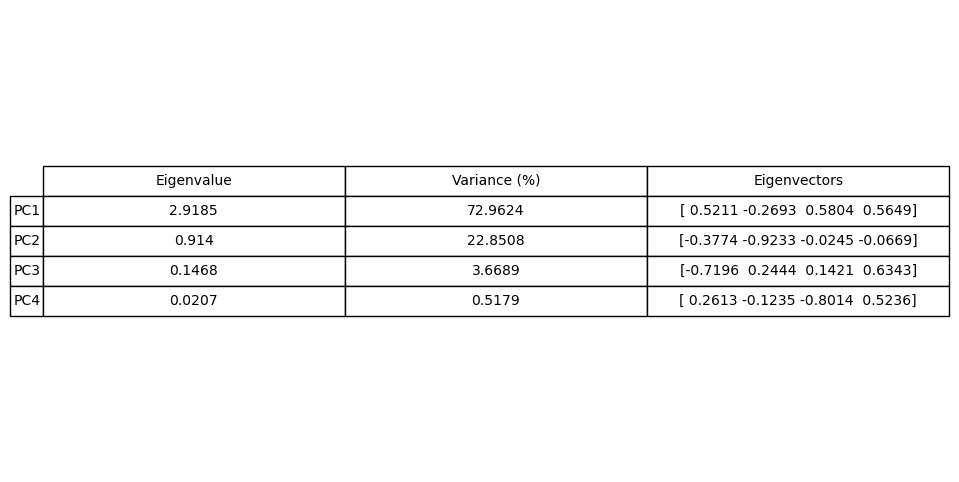

In [112]:
eigenvalues = [2.91849782, 0.91403047, 0.14675688, 0.02071484]

variance = [
    (eigenvalues[0] / 4) * 100,
    (eigenvalues[1] / 4) * 100,
    (eigenvalues[2] / 4) * 100,
    (eigenvalues[3] / 4) * 100
]

pca_table = pd.DataFrame({
    'Eigenvalue': eigenvalues,
    'Variance (%)': variance,
    'Eigenvectors': [eigenvector[:, i].round(4) for i in range(len(eigenvalue))]
}, index=['PC1', 'PC2', 'PC3', 'PC4'])


fig, ax = plt.subplots(figsize=(9, 6))
ax.axis('off')

table = ax.table(
    cellText=pca_table.round(4).values,
    colLabels=pca_table.columns,
    rowLabels=pca_table.index,
    loc='center',
    cellLoc='center'
)

table.set_fontsize(11)
table.scale(1.3, 1.8)
plt.savefig("final_table.png", bbox_inches='tight')

plt.show()

In [113]:
def sort_eigens(eigenvalues, eigenvectors):
    df_eigen = pd.DataFrame(eigenvectors)
    df_eigen['Eigenvalues'] = eigenvalues
    df_eigen.sort_values("Eigenvalues", inplace=True, ascending=False)

    sorted_eigenvalues = np.array(df_eigen['Eigenvalues'])
    sorted_eigenvectors = np.array(df_eigen.drop(columns="Eigenvalues"))

    return sorted_eigenvalues, sorted_eigenvectors

def reorient_data(df,eigenvectors):

    original_data = np.array(df)
    pca_features = np.dot(original_data, eigenvectors)
    pca_df = pd.DataFrame(pca_features)

    return pca_df


sort_eigens(eigenvalue, eigenvector)
reorient_data(df,eigenvector)


,0,1,2,3
0,2.640270,-5.204041,-2.488621,-0.117033
1,2.670730,-4.666910,-2.466898,-0.107536
2,2.454606,-4.773636,-2.288321,-0.104350
3,2.545517,-4.648463,-2.212378,-0.278417
4,2.561228,-5.258629,-2.392226,-0.155513
...,...,...,...,...
145,7.000417,-5.579908,-1.890065,-1.583173
146,6.584640,-4.935618,-2.006564,-1.675082
147,6.726747,-5.484342,-1.936433,-1.792510
148,6.748228,-5.765416,-1.404104,-1.923510


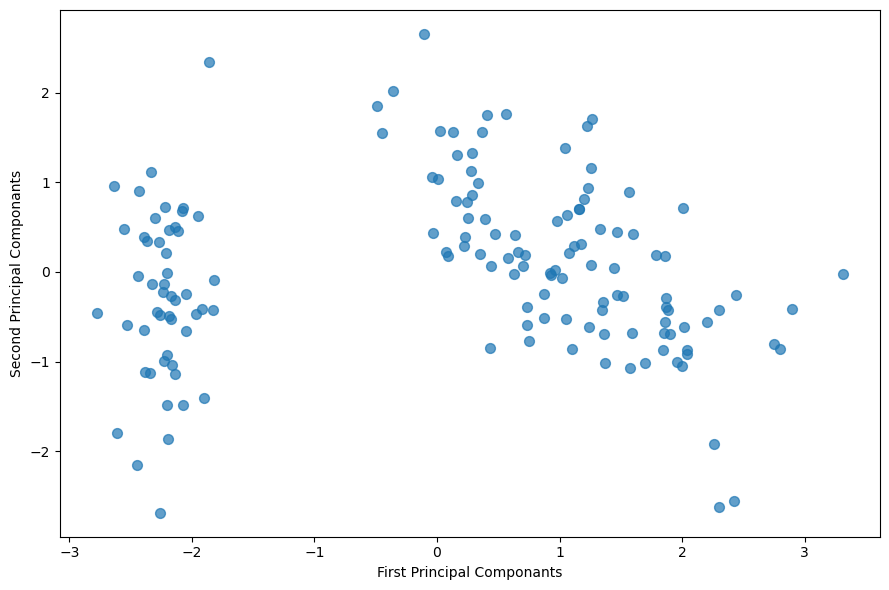

In [114]:
def sort_eigens(eigenvalues, eigenvectors):
    df_eigen = pd.DataFrame(eigenvectors)
    df_eigen['Eigenvalues'] = eigenvalues
    df_eigen.sort_values("Eigenvalues", inplace=True, ascending=False)

    sorted_eigenvalues = np.array(df_eigen['Eigenvalues'])
    sorted_eigenvectors = np.array(df_eigen.drop(columns="Eigenvalues"))

    return sorted_eigenvalues, sorted_eigenvectors


def reorient_data(df,eigenvectors):

    original_data = np.array(df)
    pca_features = np.dot(original_data, eigenvectors)
    pca_df = pd.DataFrame(pca_features)

    return pca_df
    
sorted_eigenvalues, sorted_eigenvectors = sort_eigens(
    eigenvalue, eigenvector
)

pca_df = reorient_data(std_data, sorted_eigenvectors)

explained_variance = (
    sorted_eigenvalues / sorted_eigenvalues.sum()
) * 100

plt.figure(figsize=(9, 6))

plt.scatter(
    pca_df[0],
    pca_df[1],
    alpha=0.7,
    s=50
)

plt.xlabel("First Principal Componants")
plt.ylabel("Second Principal Componants")

plt.tight_layout()

#plt.savefig("PCAS_no_colours.png")
plt.show()


    

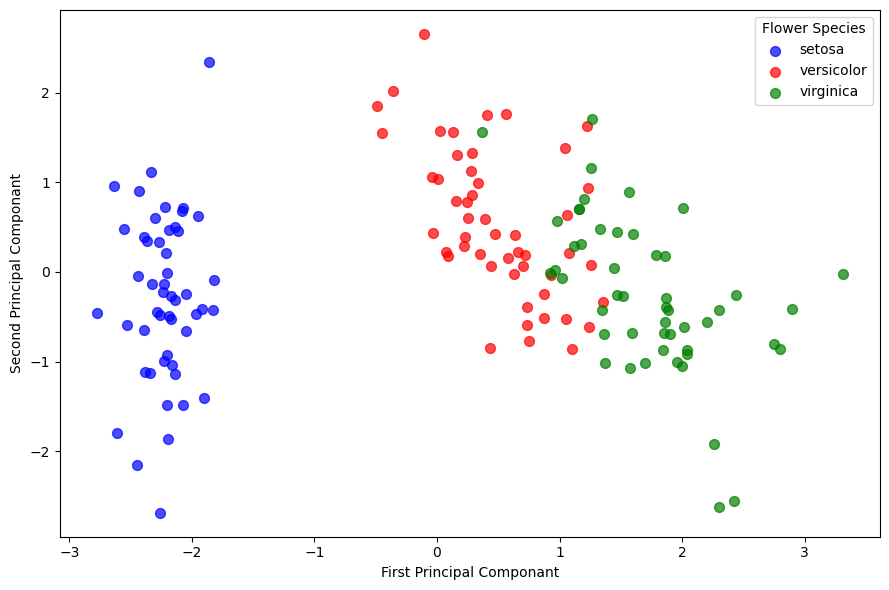

In [115]:

flower_names = data.target_names
colours = ['blue', 'red', 'green']

plt.figure(figsize=(9, 6))

for i, flower in enumerate(flower_names):
    mask = data.target == i

    plt.scatter(
        pca_df.loc[mask, 0],
        pca_df.loc[mask, 1],
        color=colours[i],
        label=flower,
        s=50,
        alpha=0.7
    )


plt.xlabel("First Principal Componant")
plt.ylabel("Second Principal Componant")

plt.legend(title='Flower Species')
plt.tight_layout()


#plt.savefig("PCAS.png")
plt.show()